# Affine registration on inverted latents

Apply the classical six-parameter affine registration from `affine_registration.ipynb` to the saved inverted latents in `results/geometric_registration/latent_undo_n5`.

Each sample has an original Gaussian latent `z` and inverted latents `z_hat` for the baseline image and for images that were shifted or rotated in pixel space. This notebook does **not** generate or invert anything new.

**Registration pair.** For each geometric condition, the template is the baseline inversion `z_hat_0` and the observation is the condition's inversion `z_hat`. A shared 2D affine is fit by multi-channel SSD on all four latent channels using the full signed values (not magnitude-only or sign-only).

**Expected transform.** A horizontal image shift of `n` pixels corresponds to a latent translation of `n / 8` (VAE scale factor 8). Vertical shifts are analogous. An image rotation of `θ` degrees corresponds to a latent rotation of `θ` about the center. Scale is 1 and shear is 0 under that ideal model. The VAE and DDIM inversion are not equivariant, so the recovered affine need not match this ideal.

**Correction.** The estimated forward map is inverted and applied to `z_hat`. The corrected latent is compared to the original Gaussian `z` and to `z_hat_0` using RMSE and Pearson correlation over every latent coordinate.


## 1. Configuration and data


In [1]:
from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy import ndimage
from scipy.optimize import differential_evolution, least_squares
from scipy.stats import pearsonr

RUN_DIR = Path("results/geometric_registration/latent_undo_n5")
LATENT_DIR = RUN_DIR / "latents"
OUTPUT_DIR = Path("results/latent_affine_registration")
FIGURES_DIR = OUTPUT_DIR / "figures"

WARP_ORDER = 1
VALID_RADIUS_FRAC = 0.32
SEED = 42

PARAM_NAMES = ["angle_deg", "scale_x", "scale_y", "shear", "tx", "ty"]
ANGLE_RANGE = (-20.0, 20.0)
SCALE_RANGE = (0.85, 1.15)
SHEAR_RANGE = (-0.2, 0.2)
TRANSLATION_RANGE = (-4.0, 4.0)
BOUNDS = [ANGLE_RANGE, SCALE_RANGE, SCALE_RANGE, SHEAR_RANGE, TRANSLATION_RANGE, TRANSLATION_RANGE]
LB = np.array([b[0] for b in BOUNDS], dtype=float)
UB = np.array([b[1] for b in BOUNDS], dtype=float)

FAMILIES = ["horizontal_translation", "vertical_translation", "rotation"]
FAMILY_TITLES = {
    "horizontal_translation": "horizontal shift (image px)",
    "vertical_translation": "vertical shift (image px)",
    "rotation": "rotation (deg)",
}

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if not LATENT_DIR.is_dir():
    raise SystemExit(f"Missing {LATENT_DIR}. Copy latent_undo_n5 from HiPerGator first.")

meta = json.loads((RUN_DIR / "metadata.json").read_text(encoding="utf-8"))
VAE_SCALE = int(meta["vae_scale_factor"])
CONDITIONS = [(row["transformation_type"], float(row["magnitude"])) for row in meta["conditions"]]
N_SAMPLES = int(meta["num_samples"])

blobs = []
for sample_id in range(N_SAMPLES):
    path = LATENT_DIR / f"sample_{sample_id:03d}.pt"
    if not path.is_file():
        raise SystemExit(f"missing {path}")
    blobs.append(torch.load(path, map_location="cpu", weights_only=True))

print(f"loaded {len(blobs)} samples from {LATENT_DIR}")
print(f"VAE scale={VAE_SCALE}, conditions={len(CONDITIONS)}")
print(f"output -> {OUTPUT_DIR.resolve()}")


loaded 5 samples from results\geometric_registration\latent_undo_n5\latents
VAE scale=8, conditions=13
output -> C:\Users\samco\OneDrive\Desktop\gaussian_rotation\results\latent_affine_registration


## 2. Multi-channel affine registration

Same parameterization as `affine_registration.ipynb`:
\(\mathbf{p}=(\theta,s_x,s_y,k,t_x,t_y)\) with
\(A=R(\theta)\begin{bmatrix}s_x & s_x k\\0 & s_y\end{bmatrix}\).
The warp is applied to each of the four channels with one shared \((A,t)\). SSD is summed over all channels on a fixed circular valid mask.

Initialization is staged for speed: an angle-only grid, a translation-only grid, a small local refinement of the better start, then bounded `least_squares`. `differential_evolution` runs only if that refine fails to beat the identity map.


In [2]:
def latent_key(kind: str, magnitude: float) -> str:
    return f"z_hat__{kind}__{magnitude:.1f}"


def as_chw(tensor) -> np.ndarray:
    array = np.asarray(tensor, dtype=np.float64)
    if array.ndim == 4 and array.shape[0] == 1:
        array = array[0]
    if array.ndim != 3:
        raise ValueError(f"expected (C,H,W), got {array.shape}")
    return array


def params_to_matrix(params: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    angle, sx, sy, shear, tx, ty = np.asarray(params, dtype=float)
    theta = np.deg2rad(angle)
    cos_t, sin_t = np.cos(theta), np.sin(theta)
    rotation = np.array([[cos_t, -sin_t], [sin_t, cos_t]], dtype=float)
    linear = np.array([[sx, sx * shear], [0.0, sy]], dtype=float)
    return rotation @ linear, np.array([tx, ty], dtype=float)


def image_center(spatial_shape: tuple[int, int]) -> np.ndarray:
    return np.array(spatial_shape, dtype=float) / 2.0 - 0.5


def warp_chw(latent: np.ndarray, matrix: np.ndarray, translation: np.ndarray) -> np.ndarray:
    center = image_center(latent.shape[-2:])
    inverse = np.linalg.inv(matrix)
    affine = np.zeros((2, 3), dtype=float)
    affine[:, :2] = inverse
    affine[:, 2] = -inverse @ (center + translation) + center
    channels = [
        ndimage.affine_transform(
            channel,
            affine,
            order=WARP_ORDER,
            mode="constant",
            cval=0.0,
            prefilter=True,
        )
        for channel in latent
    ]
    return np.stack(channels, axis=0)


def invert_params(params: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    matrix, translation = params_to_matrix(params)
    inverse = np.linalg.inv(matrix)
    return inverse, -inverse @ translation


def circular_valid_mask(spatial_shape: tuple[int, int], radius_frac: float = VALID_RADIUS_FRAC) -> np.ndarray:
    height, width = spatial_shape
    center_y, center_x = image_center(spatial_shape)
    rows, cols = np.mgrid[0:height, 0:width]
    radius = radius_frac * float(min(height, width))
    return (rows - center_y) ** 2 + (cols - center_x) ** 2 <= radius ** 2


def expected_params(kind: str, magnitude: float, vae_scale: int = VAE_SCALE) -> np.ndarray:
    if kind == "baseline" or magnitude == 0.0:
        return np.array([0.0, 1.0, 1.0, 0.0, 0.0, 0.0], dtype=float)
    if kind == "horizontal_translation":
        return np.array([0.0, 1.0, 1.0, 0.0, magnitude / vae_scale, 0.0], dtype=float)
    if kind == "vertical_translation":
        return np.array([0.0, 1.0, 1.0, 0.0, 0.0, magnitude / vae_scale], dtype=float)
    if kind == "rotation":
        return np.array([magnitude, 1.0, 1.0, 0.0, 0.0, 0.0], dtype=float)
    raise ValueError(kind)


def full_latent_rmse(a: np.ndarray, b: np.ndarray, mask: np.ndarray | None = None) -> float:
    if mask is None:
        residual = a.ravel() - b.ravel()
    else:
        residual = a[:, mask].ravel() - b[:, mask].ravel()
    return float(np.sqrt(np.mean(residual ** 2)))


def full_latent_corr(a: np.ndarray, b: np.ndarray, mask: np.ndarray | None = None) -> float:
    if mask is None:
        left, right = a.ravel(), b.ravel()
    else:
        left, right = a[:, mask].ravel(), b[:, mask].ravel()
    return float(pearsonr(left, right).statistic)


SHAPE = as_chw(blobs[0]["z"]).shape
VALID_MASK = circular_valid_mask(SHAPE[-2:])
print(f"latent shape {SHAPE}, valid pixels/channel={int(VALID_MASK.sum())} ({100 * VALID_MASK.mean():.1f}%)")


latent shape (4, 64, 64), valid pixels/channel=1304 (31.8%)


In [3]:
def residual_vector(template: np.ndarray, observation: np.ndarray, params: np.ndarray, mask: np.ndarray) -> np.ndarray:
    warped = warp_chw(template, *params_to_matrix(params))
    return (warped[:, mask] - observation[:, mask]).ravel()


def ssd_cost(template: np.ndarray, observation: np.ndarray, params: np.ndarray, mask: np.ndarray) -> float:
    residual = residual_vector(template, observation, params, mask)
    return float(residual @ residual)


def coarse_initialize(template: np.ndarray, observation: np.ndarray, mask: np.ndarray) -> np.ndarray:
    identity = np.array([0.0, 1.0, 1.0, 0.0, 0.0, 0.0], dtype=float)
    best_params = identity.copy()
    best_cost = ssd_cost(template, observation, best_params, mask)

    for angle in np.arange(ANGLE_RANGE[0], ANGLE_RANGE[1] + 0.5, 2.0):
        params = np.array([angle, 1.0, 1.0, 0.0, 0.0, 0.0], dtype=float)
        cost = ssd_cost(template, observation, params, mask)
        if cost < best_cost:
            best_cost = cost
            best_params = params

    for tx in np.arange(TRANSLATION_RANGE[0], TRANSLATION_RANGE[1] + 0.25, 0.5):
        for ty in np.arange(TRANSLATION_RANGE[0], TRANSLATION_RANGE[1] + 0.25, 0.5):
            params = np.array([0.0, 1.0, 1.0, 0.0, tx, ty], dtype=float)
            cost = ssd_cost(template, observation, params, mask)
            if cost < best_cost:
                best_cost = cost
                best_params = params

    # Local product search around the current best.
    angle0, _, _, _, tx0, ty0 = best_params
    for angle in np.unique(np.clip([angle0 - 2, angle0, angle0 + 2], ANGLE_RANGE[0], ANGLE_RANGE[1])):
        for tx in np.unique(np.clip([tx0 - 0.5, tx0, tx0 + 0.5], TRANSLATION_RANGE[0], TRANSLATION_RANGE[1])):
            for ty in np.unique(np.clip([ty0 - 0.5, ty0, ty0 + 0.5], TRANSLATION_RANGE[0], TRANSLATION_RANGE[1])):
                params = np.array([angle, 1.0, 1.0, 0.0, tx, ty], dtype=float)
                cost = ssd_cost(template, observation, params, mask)
                if cost < best_cost:
                    best_cost = cost
                    best_params = params
    return best_params


def register_affine(template: np.ndarray, observation: np.ndarray, mask: np.ndarray) -> dict:
    started = time.perf_counter()
    init = coarse_initialize(template, observation, mask)

    def fun(params: np.ndarray) -> np.ndarray:
        return residual_vector(template, observation, params, mask)

    identity = np.array([0.0, 1.0, 1.0, 0.0, 0.0, 0.0], dtype=float)
    identity_rmse = float(np.sqrt(np.mean(fun(identity) ** 2)))

    refined = least_squares(
        fun,
        init,
        bounds=(LB, UB),
        xtol=1e-8,
        ftol=1e-8,
        gtol=1e-8,
        max_nfev=400,
    )
    estimate = refined.x.copy()
    rmse = float(np.sqrt(np.mean(fun(estimate) ** 2)))
    method = "coarse+least_squares"

    if rmse > 0.98 * identity_rmse:
        de = differential_evolution(
            lambda params: ssd_cost(template, observation, params, mask),
            BOUNDS,
            polish=True,
            tol=1e-5,
            popsize=5,
            seed=SEED,
        )
        refined = least_squares(fun, de.x, bounds=(LB, UB), xtol=1e-8, ftol=1e-8, max_nfev=200)
        estimate = refined.x.copy()
        rmse = float(np.sqrt(np.mean(fun(estimate) ** 2)))
        method = "differential_evolution+least_squares"

    return {
        "estimated_params": estimate,
        "init_params": init,
        "rmse": rmse,
        "identity_rmse": identity_rmse,
        "method": method,
        "runtime_s": time.perf_counter() - started,
    }


def apply_inverse(latent: np.ndarray, params: np.ndarray) -> np.ndarray:
    inverse_matrix, inverse_translation = invert_params(params)
    return warp_chw(latent, inverse_matrix, inverse_translation)


## 3. Run registration on every saved condition

For each sample and each condition, fit an affine taking `z_hat_0` to `z_hat`, invert that affine on `z_hat`, and score the full latent against `z` and against `z_hat_0`. Baseline uses the identity map.


In [4]:
rows = []
started = time.perf_counter()
jobs = [(sid, kind, mag) for sid in range(N_SAMPLES) for kind, mag in CONDITIONS]
for index, (sample_id, kind, magnitude) in enumerate(jobs, start=1):
    blob = blobs[sample_id]
    z = as_chw(blob["z"])
    baseline = as_chw(blob[latent_key("baseline", 0.0)])
    observation = as_chw(blob[latent_key(kind, magnitude)])
    expected = expected_params(kind, magnitude)

    if kind == "baseline":
        estimate = expected.copy()
        method = "identity"
        runtime = 0.0
        reg_rmse = full_latent_rmse(baseline, observation, VALID_MASK)
        identity_rmse = reg_rmse
    else:
        fit = register_affine(baseline, observation, VALID_MASK)
        estimate = fit["estimated_params"]
        method = fit["method"]
        runtime = fit["runtime_s"]
        reg_rmse = fit["rmse"]
        identity_rmse = fit["identity_rmse"]

    corrected = observation if kind == "baseline" else apply_inverse(observation, estimate)
    oracle_corrected = apply_inverse(observation, expected)

    row = {
        "sample_id": sample_id,
        "transformation_type": kind,
        "magnitude": magnitude,
        "method": method,
        "runtime_s": runtime,
        "registration_rmse": reg_rmse,
        "identity_rmse": identity_rmse,
        "corr_zhat_vs_z": full_latent_corr(observation, z),
        "corr_corrected_vs_z": full_latent_corr(corrected, z),
        "corr_oracle_vs_z": full_latent_corr(oracle_corrected, z),
        "corr_corrected_vs_baseline": full_latent_corr(corrected, baseline),
        "corr_zhat_vs_baseline": full_latent_corr(observation, baseline),
        "rmse_zhat_vs_z": full_latent_rmse(observation, z),
        "rmse_corrected_vs_z": full_latent_rmse(corrected, z),
        "rmse_oracle_vs_z": full_latent_rmse(oracle_corrected, z),
        "rmse_corrected_vs_baseline": full_latent_rmse(corrected, baseline),
        "param_mae": float(np.mean(np.abs(estimate - expected))),
        "angle_err": float(abs(estimate[0] - expected[0])),
        "tx_err": float(abs(estimate[4] - expected[4])),
        "ty_err": float(abs(estimate[5] - expected[5])),
        "scale_x_err": float(abs(estimate[1] - expected[1])),
        "scale_y_err": float(abs(estimate[2] - expected[2])),
        "shear_err": float(abs(estimate[3] - expected[3])),
    }
    for name, truth, hat in zip(PARAM_NAMES, expected, estimate):
        row[f"true_{name}"] = float(truth)
        row[f"est_{name}"] = float(hat)
    rows.append(row)

    if index == 1 or index == len(jobs) or index % 5 == 0:
        elapsed = time.perf_counter() - started
        eta = elapsed / index * (len(jobs) - index)
        print(
            f"[{index}/{len(jobs)}] sample {sample_id} {kind} {magnitude:g} | "
            f"method={method} ang={estimate[0]:.2f} (exp {expected[0]:.2f}) "
            f"tx={estimate[4]:.2f} ty={estimate[5]:.2f} | "
            f"corr zhat/z={row['corr_zhat_vs_z']:.3f} corrected/z={row['corr_corrected_vs_z']:.3f} | "
            f"elapsed {elapsed:.1f}s eta {eta:.1f}s",
            flush=True,
        )

results = pd.DataFrame(rows)
results_path = OUTPUT_DIR / "trial_results.csv"
results.to_csv(results_path, index=False)
print(f"wrote {results_path} ({len(results)} rows)")
print(f"DE fallback rate on non-baseline rows: {results.loc[results.transformation_type != 'baseline', 'method'].str.startswith('differential').mean():.1%}")


[1/65] sample 0 baseline 0 | method=identity ang=0.00 (exp 0.00) tx=0.00 ty=0.00 | corr zhat/z=0.870 corrected/z=0.870 | elapsed 0.0s eta 1.5s


[5/65] sample 0 horizontal_translation 10 | method=coarse+least_squares ang=0.03 (exp 0.00) tx=0.01 ty=1.12 | corr zhat/z=0.042 corrected/z=0.620 | elapsed 13.8s eta 165.9s


[10/65] sample 0 rotation 1 | method=coarse+least_squares ang=0.63 (exp 1.00) tx=-0.04 ty=-0.01 | corr zhat/z=0.375 corrected/z=0.419 | elapsed 25.4s eta 139.5s


[15/65] sample 1 horizontal_translation 1 | method=differential_evolution+least_squares ang=0.02 (exp 0.00) tx=0.03 ty=-0.04 | corr zhat/z=0.830 corrected/z=0.826 | elapsed 36.2s eta 120.6s


[20/65] sample 1 vertical_translation 2 | method=coarse+least_squares ang=-0.05 (exp 0.00) tx=0.13 ty=0.11 | corr zhat/z=0.585 corrected/z=0.574 | elapsed 49.2s eta 110.6s


...

[50/65] sample 3 rotation 2 | method=coarse+least_squares ang=2.05 (exp 2.00) tx=-0.01 ty=-0.00 | corr zhat/z=0.091 corrected/z=0.423 | elapsed 108.7s eta 32.6s


[55/65] sample 4 horizontal_translation 2 | method=coarse+least_squares ang=0.03 (exp 0.00) tx=0.10 ty=0.10 | corr zhat/z=0.720 corrected/z=0.703 | elapsed 120.2s eta 21.9s


[60/65] sample 4 vertical_translation 5 | method=coarse+least_squares ang=0.92 (exp 0.00) tx=0.69 ty=0.05 | corr zhat/z=0.082 corrected/z=0.310 | elapsed 133.0s eta 11.1s


[65/65] sample 4 rotation 10 | method=coarse+least_squares ang=9.93 (exp 10.00) tx=-0.02 ty=0.01 | corr zhat/z=0.010 corrected/z=0.403 | elapsed 139.1s eta 0.0s


wrote results\latent_affine_registration\trial_results.csv (65 rows)
DE fallback rate on non-baseline rows: 15.0%


## 4. How well is the affine recovered?

Expected parameters use the ideal latent-space model (`n/8` for shifts, same angle for rotations). Errors mix degrees, dimensionless scale/shear, and latent pixels.


   transformation_type  magnitude  n  mean_angle_err  mean_tx_err  mean_ty_err  mean_scale_x_err  mean_shear_err  mean_param_mae  mean_est_angle  mean_est_tx  mean_est_ty  mean_true_tx  mean_true_ty  mean_true_angle
              baseline        0.0  5          0.0000       0.0000       0.0000            0.0000          0.0000          0.0000          0.0000       0.0000       0.0000         0.000         0.000              0.0
horizontal_translation        1.0  5          0.0588       0.1186       0.0252            0.0011          0.0014          0.0344          0.0305       0.0064      -0.0215         0.125         0.000              0.0
horizontal_translation        2.0  5          0.0835       0.2009       0.0944            0.0014          0.0014          0.0641          0.0224       0.0491       0.0420         0.250         0.000              0.0
horizontal_translation        5.0  5          0.3726       0.4919       0.7714            0.0063          0.0060          0.2749        

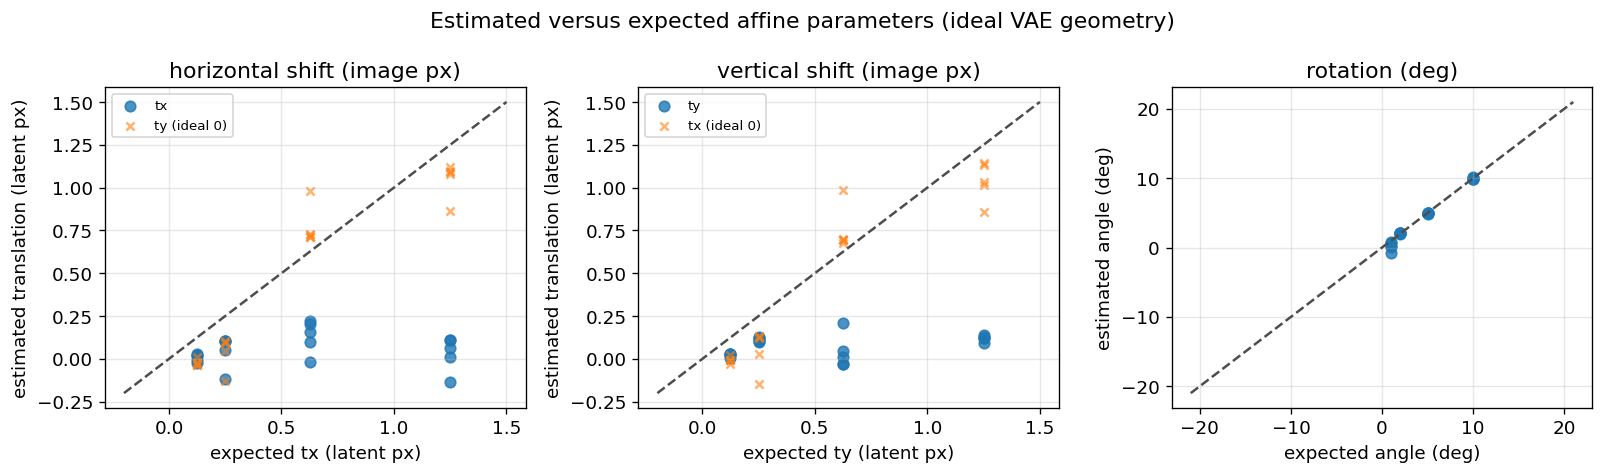

In [5]:
param_summary = (
    results.groupby(["transformation_type", "magnitude"], observed=True)
    .agg(
        n=("sample_id", "count"),
        mean_angle_err=("angle_err", "mean"),
        mean_tx_err=("tx_err", "mean"),
        mean_ty_err=("ty_err", "mean"),
        mean_scale_x_err=("scale_x_err", "mean"),
        mean_shear_err=("shear_err", "mean"),
        mean_param_mae=("param_mae", "mean"),
        mean_est_angle=("est_angle_deg", "mean"),
        mean_est_tx=("est_tx", "mean"),
        mean_est_ty=("est_ty", "mean"),
        mean_true_tx=("true_tx", "mean"),
        mean_true_ty=("true_ty", "mean"),
        mean_true_angle=("true_angle_deg", "mean"),
    )
    .reset_index()
)
print(param_summary.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0))
for ax, kind in zip(axes, FAMILIES):
    block = results.loc[results.transformation_type == kind]
    if kind == "rotation":
        ax.scatter(block.true_angle_deg, block.est_angle_deg, s=40, alpha=0.8)
        lim = (ANGLE_RANGE[0] - 1, ANGLE_RANGE[1] + 1)
        ax.plot(lim, lim, ls="--", color="0.3")
        ax.set_xlabel("expected angle (deg)")
        ax.set_ylabel("estimated angle (deg)")
    elif kind == "horizontal_translation":
        ax.scatter(block.true_tx, block.est_tx, s=40, alpha=0.8, label="tx")
        ax.scatter(block.true_tx, block.est_ty, s=24, alpha=0.6, marker="x", label="ty (ideal 0)")
        ax.plot([-0.2, 1.5], [-0.2, 1.5], ls="--", color="0.3")
        ax.set_xlabel("expected tx (latent px)")
        ax.set_ylabel("estimated translation (latent px)")
        ax.legend(fontsize=8)
    else:
        ax.scatter(block.true_ty, block.est_ty, s=40, alpha=0.8, label="ty")
        ax.scatter(block.true_ty, block.est_tx, s=24, alpha=0.6, marker="x", label="tx (ideal 0)")
        ax.plot([-0.2, 1.5], [-0.2, 1.5], ls="--", color="0.3")
        ax.set_xlabel("expected ty (latent px)")
        ax.set_ylabel("estimated translation (latent px)")
        ax.legend(fontsize=8)
    ax.set_title(FAMILY_TITLES[kind])
fig.suptitle("Estimated versus expected affine parameters (ideal VAE geometry)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "estimated_vs_expected_params.png", bbox_inches="tight")
plt.show()


## 5. Does the corrected latent match the original `z`?

All scores use the full signed latent. `corr_zhat_vs_z` is the raw inversion. `corr_corrected_vs_z` uses the **estimated** inverse affine. `corr_oracle_vs_z` uses the ideal inverse (`-n/8` or `-θ`).


   transformation_type  magnitude  corr_zhat_vs_z  corr_corrected_vs_z  corr_oracle_vs_z  corr_corrected_vs_baseline  rmse_zhat_vs_z  rmse_corrected_vs_z  rmse_oracle_vs_z  gain_vs_raw
              baseline        0.0          0.8919               0.8919            0.8919                      1.0000          0.4585               0.4585            0.4585       0.0000
horizontal_translation        1.0          0.8432               0.8362            0.8253                      0.9209          0.5546               0.5518            0.5660      -0.0070
horizontal_translation        2.0          0.6974               0.6802            0.6542                      0.7402          0.7715               0.7408            0.7667      -0.0172
horizontal_translation        5.0          0.1185               0.4311            0.0825                      0.4717          1.3195               0.9248            1.1819       0.3127
horizontal_translation       10.0          0.0338               0.6756     

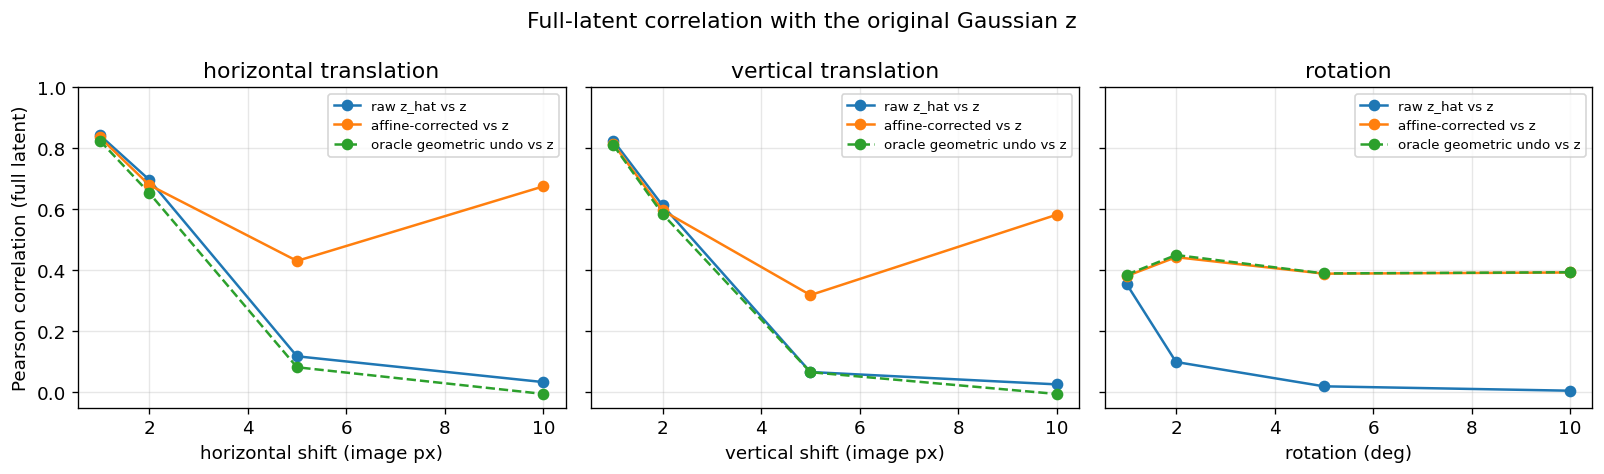

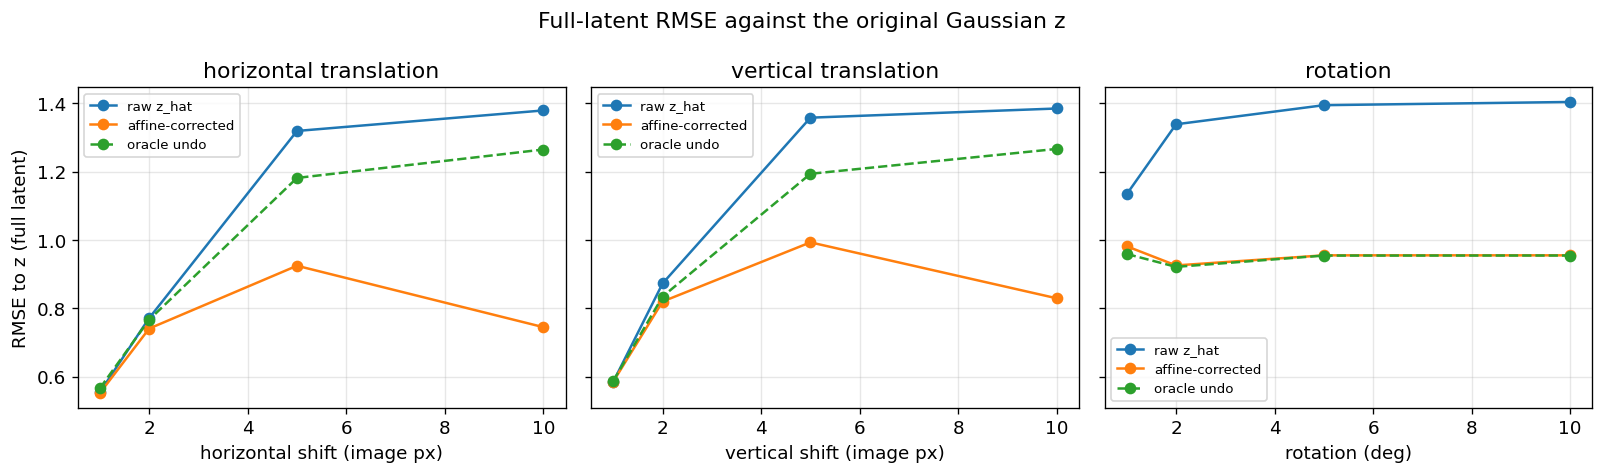

In [6]:
score_summary = (
    results.groupby(["transformation_type", "magnitude"], observed=True)
    .agg(
        corr_zhat_vs_z=("corr_zhat_vs_z", "mean"),
        corr_corrected_vs_z=("corr_corrected_vs_z", "mean"),
        corr_oracle_vs_z=("corr_oracle_vs_z", "mean"),
        corr_corrected_vs_baseline=("corr_corrected_vs_baseline", "mean"),
        rmse_zhat_vs_z=("rmse_zhat_vs_z", "mean"),
        rmse_corrected_vs_z=("rmse_corrected_vs_z", "mean"),
        rmse_oracle_vs_z=("rmse_oracle_vs_z", "mean"),
    )
    .reset_index()
)
score_summary["gain_vs_raw"] = score_summary.corr_corrected_vs_z - score_summary.corr_zhat_vs_z
print(score_summary.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0), sharey=True)
for ax, kind in zip(axes, FAMILIES):
    block = score_summary.loc[score_summary.transformation_type == kind].sort_values("magnitude")
    ax.plot(block.magnitude, block.corr_zhat_vs_z, "-o", label="raw z_hat vs z")
    ax.plot(block.magnitude, block.corr_corrected_vs_z, "-o", label="affine-corrected vs z")
    ax.plot(block.magnitude, block.corr_oracle_vs_z, "--o", label="oracle geometric undo vs z")
    ax.set_xlabel(FAMILY_TITLES[kind])
    ax.set_title(kind.replace("_", " "))
    ax.set_ylim(-0.05, 1.0)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Pearson correlation (full latent)")
fig.suptitle("Full-latent correlation with the original Gaussian z")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "correlation_vs_z.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0), sharey=True)
for ax, kind in zip(axes, FAMILIES):
    block = score_summary.loc[score_summary.transformation_type == kind].sort_values("magnitude")
    ax.plot(block.magnitude, block.rmse_zhat_vs_z, "-o", label="raw z_hat")
    ax.plot(block.magnitude, block.rmse_corrected_vs_z, "-o", label="affine-corrected")
    ax.plot(block.magnitude, block.rmse_oracle_vs_z, "--o", label="oracle undo")
    ax.set_xlabel(FAMILY_TITLES[kind])
    ax.set_title(kind.replace("_", " "))
    ax.legend(fontsize=8)
axes[0].set_ylabel("RMSE to z (full latent)")
fig.suptitle("Full-latent RMSE against the original Gaussian z")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "rmse_vs_z.png", bbox_inches="tight")
plt.show()


## 6. Example: sample 0, channels 0–1

Baseline inversion, transformed inversion, and the affine-corrected latent for one translation and one rotation.


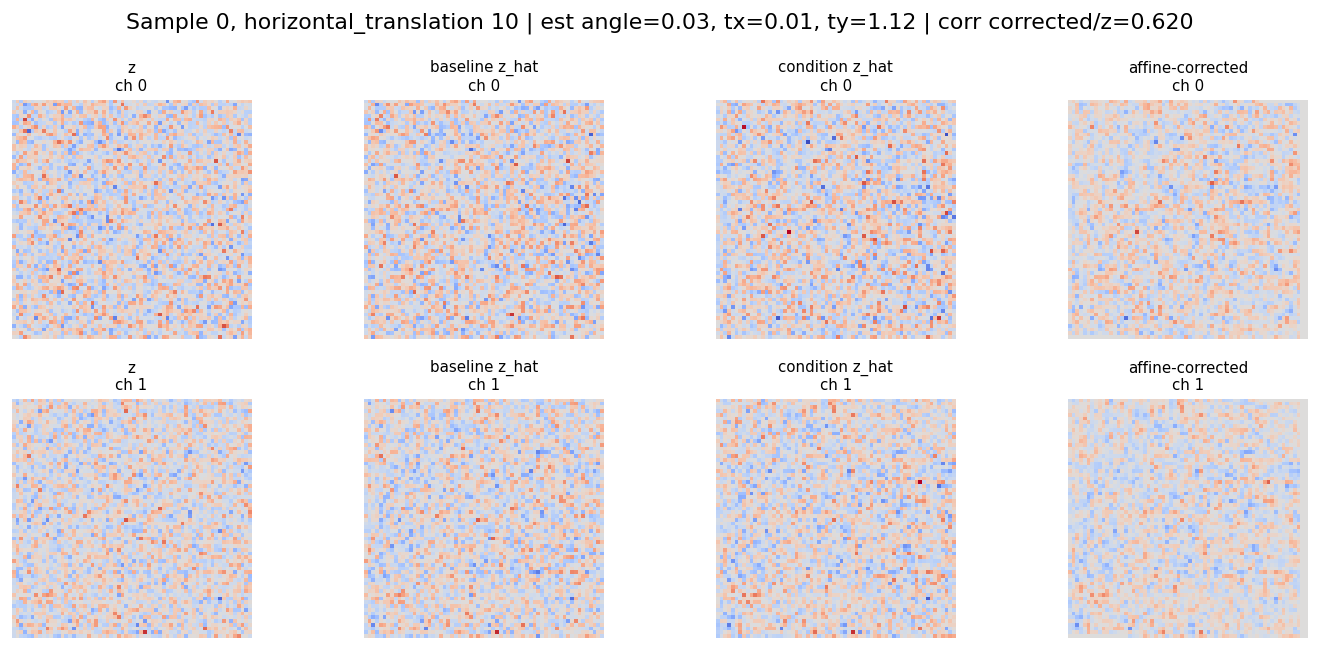

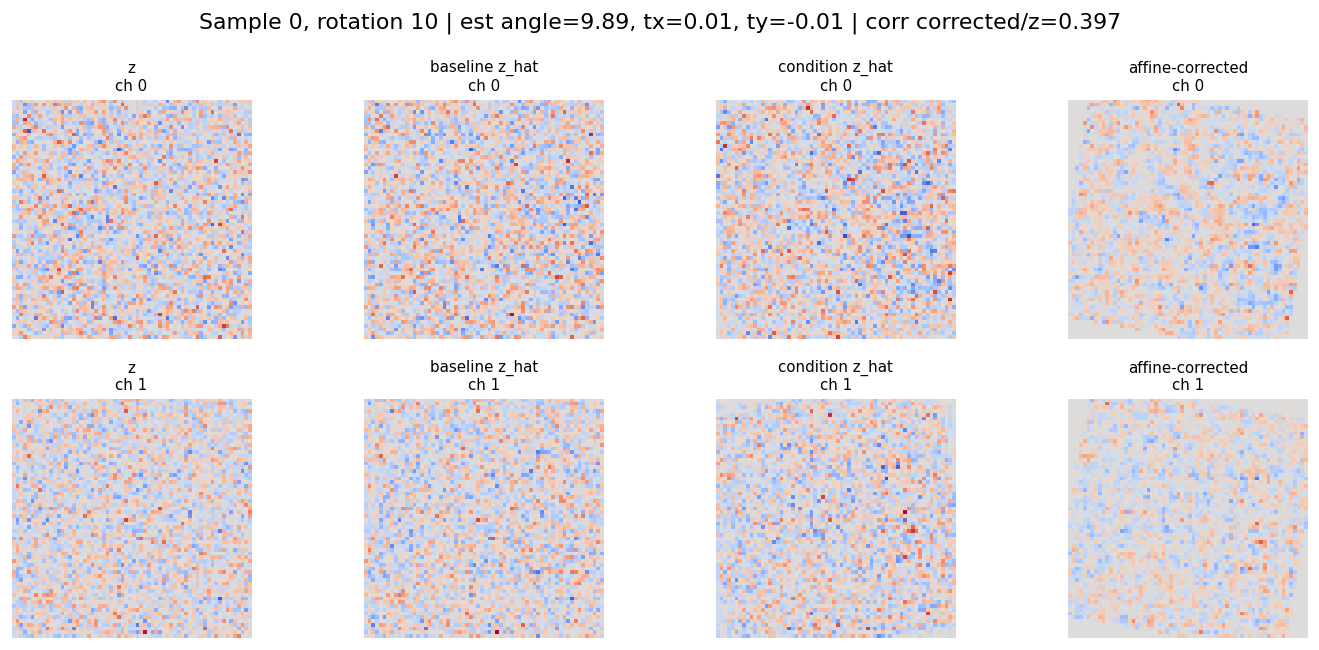

In [7]:
def show_case(kind: str, magnitude: float) -> None:
    blob = blobs[0]
    z = as_chw(blob["z"])
    baseline = as_chw(blob[latent_key("baseline", 0.0)])
    observation = as_chw(blob[latent_key(kind, magnitude)])
    row = results.loc[
        (results.sample_id == 0)
        & (results.transformation_type == kind)
        & np.isclose(results.magnitude, magnitude)
    ].iloc[0]
    estimate = np.array([row[f"est_{name}"] for name in PARAM_NAMES], dtype=float)
    corrected = apply_inverse(observation, estimate)

    panels = [
        ("z", z),
        ("baseline z_hat", baseline),
        ("condition z_hat", observation),
        ("affine-corrected", corrected),
    ]
    fig, axes = plt.subplots(2, 4, figsize=(12, 5.5))
    for channel in (0, 1):
        limit = max(float(np.max(np.abs(img[channel]))) for _, img in panels)
        limit = max(limit, 1e-6)
        for col, (title, img) in enumerate(panels):
            axes[channel, col].imshow(img[channel], cmap="coolwarm", vmin=-limit, vmax=limit)
            axes[channel, col].set_title(f"{title}\nch {channel}", fontsize=9)
            axes[channel, col].axis("off")
    fig.suptitle(
        f"Sample 0, {kind} {magnitude:g} | est angle={row.est_angle_deg:.2f}, "
        f"tx={row.est_tx:.2f}, ty={row.est_ty:.2f} | corr corrected/z={row.corr_corrected_vs_z:.3f}"
    )
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"example_sample0_{kind}_{magnitude:g}.png", bbox_inches="tight")
    plt.show()


show_case("horizontal_translation", 10.0)
show_case("rotation", 10.0)


## 7. Interpretation


In [8]:
metadata = {
    "source_run": str(RUN_DIR),
    "n_samples": N_SAMPLES,
    "vae_scale_factor": VAE_SCALE,
    "registration": "shared affine on all 4 latent channels; template=baseline z_hat; observation=condition z_hat",
    "scores": "full-latent Pearson correlation and RMSE (signed values, all coordinates)",
    "expected_transform": "horizontal/vertical: translation magnitude/8; rotation: same angle; scale=1 shear=0",
}
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")
score_summary.to_csv(OUTPUT_DIR / "score_summary.csv", index=False)
param_summary.to_csv(OUTPUT_DIR / "param_summary.csv", index=False)

print("Interpretation")
base = results.loc[results.transformation_type == "baseline"]
print(
    f"- Baseline: mean corr(z_hat, z)={base.corr_zhat_vs_z.mean():.3f}. "
    "That is the inversion ceiling before any geometric mismatch."
)
for kind in FAMILIES:
    block = score_summary.loc[score_summary.transformation_type == kind].sort_values("magnitude")
    best = block.loc[block.gain_vs_raw.idxmax()]
    print(
        f"- {kind}: largest mean correlation gain from affine correction is "
        f"{best.gain_vs_raw:.3f} at magnitude {best.magnitude:g} "
        f"(raw {best.corr_zhat_vs_z:.3f} -> corrected {best.corr_corrected_vs_z:.3f}; "
        f"oracle {best.corr_oracle_vs_z:.3f})."
    )
rot = results.loc[results.transformation_type == "rotation"]
print(
    f"- Rotations: mean |angle error|={rot.angle_err.mean():.3f} deg. "
    "Angle is the parameter the affine fit recovers most cleanly."
)
shift = results.loc[results.transformation_type.isin(["horizontal_translation", "vertical_translation"])]
print(
    f"- Translations: mean |tx error|={shift.tx_err.mean():.3f}, mean |ty error|={shift.ty_err.mean():.3f} latent px. "
    "A few image pixels are a fraction of a latent pixel and compete with inversion noise."
)
print(f"- Wrote summaries under {OUTPUT_DIR}")


Interpretation
- Baseline: mean corr(z_hat, z)=0.892. That is the inversion ceiling before any geometric mismatch.
- horizontal_translation: largest mean correlation gain from affine correction is 0.642 at magnitude 10 (raw 0.034 -> corrected 0.676; oracle -0.005).
- vertical_translation: largest mean correlation gain from affine correction is 0.556 at magnitude 10 (raw 0.026 -> corrected 0.583; oracle -0.005).
- rotation: largest mean correlation gain from affine correction is 0.388 at magnitude 10 (raw 0.006 -> corrected 0.393; oracle 0.394).
- Rotations: mean |angle error|=0.270 deg. Angle is the parameter the affine fit recovers most cleanly.
- Translations: mean |tx error|=0.493, mean |ty error|=0.487 latent px. A few image pixels are a fraction of a latent pixel and compete with inversion noise.
- Wrote summaries under results\latent_affine_registration
